# DeepONet for the 1D committor problem

*This is Claude's (Opus 5.5) revision of Cameron's notebook*

**References**

[1] Lu Lu, Pengzhan Jin, George Em Karniadakis, *DeepONet: Learning nonlinear operators for identifying differential equations based on the universal approximation theorem of operators*, https://arxiv.org/abs/1910.03193

[2] Lu Lu, Pengzhan Jin, Guofei Pang, Zhongqiang Zhang, George Em Karniadakis, *Learning nonlinear operators via DeepONet based on the universal approximation theorem of operators*,
Nature Machine Intelligence volume 3, pages 218–229 (2021), https://doi.org/10.1038/s42256-021-00302-5

[3] Lloyd N. Trefethen, *Spectral Methods in MATLAB*, SIAM 2000.

---

### What changed compared with the previous version of this notebook

| | previous version | this version |
|---|---|---|
| Gaussian random field sampler | `np.linalg.eig` + `np.diag` on an `(m,1)` array. **Bug:** the matrix was not $\mathrm{Cov}^{1/2}$, so the samples were rough and 2–6× too large | `np.linalg.eigh` (symmetric), square root checked to $10^{-10}$ |
| Training functions | 100 functions × 100 points (each $u$ copied 100 times) | 2000 functions × 100 points (each $u$ stored once) |
| Mini-batches | rows of a `(10000, 102)` table, batch size 156, `requires_grad` on the data | 64 *functions* per batch: one branch evaluation per function |
| LR schedule | `MultiStepLR` with milestones at 1000, 3000 and 5000 epochs, never reached in 1000 epochs | cosine decay from $10^{-3}$ to $10^{-5}$ |
| Output layer | $\sigma(\langle b, t\rangle)$, no bias | trainable bias $b_0$, and the boundary conditions are imposed exactly (sigmoid kept as an option) |
| Reference solver | Clenshaw via one dense triangular solve per point | same Chebyshev method with vectorized Clenshaw (about 100× faster), checked against quadrature |
| Evaluation | weights copied by hand into NumPy | `torch.no_grad()`, with a generic NumPy version as an optional check |
| `TrunkNN.forward` | used the global variable `y` instead of its argument | fixed |

The results table at the end compares the errors with the previous version.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
from scipy.linalg import toeplitz
from Committor1D_helpers import solve1Dcommittor, committor_quadrature

# Fix the random seeds so that the results can be reproduced.
np.random.seed(0)
torch.manual_seed(0)
rng = np.random.default_rng(0)
print("torch", torch.__version__, "| CPU threads:", torch.get_num_threads())

torch 2.13.0 | CPU threads: 8


## 1. The problem

A particle in 1D evolves according to the overdamped Langevin SDE
$$ dX_t = -V'(X_t)\,dt + \sqrt{2\beta^{-1}}\,dW_t,\quad X_t\in\mathbb{R}.$$
Let $A:=\{x\le -1\}$ and $B:=\{x\ge 1\}$. The **committor** $q(x)$ is the probability that the particle starting at $x\in[-1,1]$ reaches $B$ **before** $A$. It solves
$$ q''(x) - \beta V'(x)\,q'(x) = 0,\quad q(-1) = 0,\quad q(1) = 1.$$
(The boundary conditions $q=0$ on $A$ and $q=1$ on $B$ make $q$ the probability of hitting $B$ first. The probability of hitting $A$ first is $1-q$.)

In 1D the solution has a closed form:
$$q(x) = \frac{\int_{-1}^x e^{\beta V(y)}dy}{\int_{-1}^1 e^{\beta V(y)}dy}.$$
We still compute the reference solutions with a Chebyshev spectral method, which works directly with the force $u = V'$ and is very accurate. The closed form is used as an independent check.

**Operator learning task.** Let $u := V'$. We want to learn the solution operator
$$\mathcal{G}: u \mapsto q = \mathcal{G}(u),$$
so that a single trained network returns the committor of a *new* potential without solving the BVP. We set $\beta = 1$.

## 2. Sampling input functions from a Gaussian random field

The forces $u = V'$ are drawn from a zero-mean Gaussian random field (GRF) with squared-exponential covariance
$$\mathrm{Cov}(x_1,x_2) = \exp\left(-\frac{|x_1-x_2|^2}{2l^2}\right),\qquad l = 0.5 .$$
On the sensor grid $x_1,\dots,x_{N_x}$ ($N_x = 100$) we form the covariance matrix $C$ and draw samples as
$$u = C^{1/2} w, \qquad w\sim\mathcal{N}(0, I),$$
which gives $\mathbb{E}[uu^\top] = C^{1/2}C^{1/2} = C$.

$C$ is symmetric positive semi-definite, so we use `np.linalg.eigh`, which returns real eigenvalues and an **orthonormal** eigenbasis: $C = Q\Lambda Q^\top$ and $C^{1/2} = Q\Lambda^{1/2}Q^\top$. The squared-exponential kernel is very smooth, so most eigenvalues are at round-off level. We drop eigenvalues below $10^{-8}$, which makes the samples numerically smooth.

In [2]:
l = 0.5
xmin, xmax = -1.0, 1.0
Nx = 100                      # number of sensors = input dimension of the branch net
x = np.linspace(xmin, xmax, Nx)

aux = np.exp(-0.5 * (x - xmin)**2 / l**2)
Cov = toeplitz(aux)           # Cov[i,j] = exp(-|x_i - x_j|^2 / (2 l^2))

E, Q = np.linalg.eigh(Cov)    # symmetric -> real eigenvalues, orthonormal eigenvectors
keep = E > 1e-8
Cov_sqrt = Q[:, keep] @ np.diag(np.sqrt(E[keep])) @ Q[:, keep].T
print(f"kept {keep.sum()} of {Nx} eigenvalues")
print(f"relative error ||Cov_sqrt^2 - Cov|| / ||Cov|| = "
      f"{np.linalg.norm(Cov_sqrt @ Cov_sqrt - Cov) / np.linalg.norm(Cov):.1e}")

def sample_grf(n):
    # Return n GRF samples as rows of an (n, Nx) array.
    return (Cov_sqrt @ rng.standard_normal((Nx, n))).T

kept 13 of 100 eigenvalues
relative error ||Cov_sqrt^2 - Cov|| / ||Cov|| = 6.6e-11


### What went wrong in the previous sampler

The previous version used
```python
E,V = np.linalg.eig(Cov)
ind = np.argwhere(np.real(E)>1e-8)          # shape (m, 1), not (m,)
Cov_sqrt = V[:,ind]@np.diag(np.sqrt(np.real(E[ind])))@np.transpose(V[:,ind])
```
There are two problems.
1. `ind` has shape `(m,1)`, so `E[ind]` is a 2D array, and **`np.diag` of a 2D array extracts its diagonal** (a single number) instead of building a diagonal matrix. The product then broadcasts silently into something that is not $C^{1/2}$.
2. `np.linalg.eig` doesn't assume symmetry. For the cluster of round-off-level eigenvalues it returns eigenvectors that are far from orthogonal, so $V\Lambda^{1/2}V^\top$ would be wrong even with the correct `np.diag`.

The cell below rebuilds the old matrix and compares the two samplers. The old samples are rough, and their standard deviation is about 6 near the endpoints instead of 1. The network was therefore trained on a different and harder family of functions than intended, and the double-well force lay outside that family.

||Cov_sqrt_old^2 - Cov|| / ||Cov|| = 2.74
pointwise std of u  (old): min 2.12, max 6.14   (should be 1)
pointwise std of u  (new): min 0.99, max 1.01


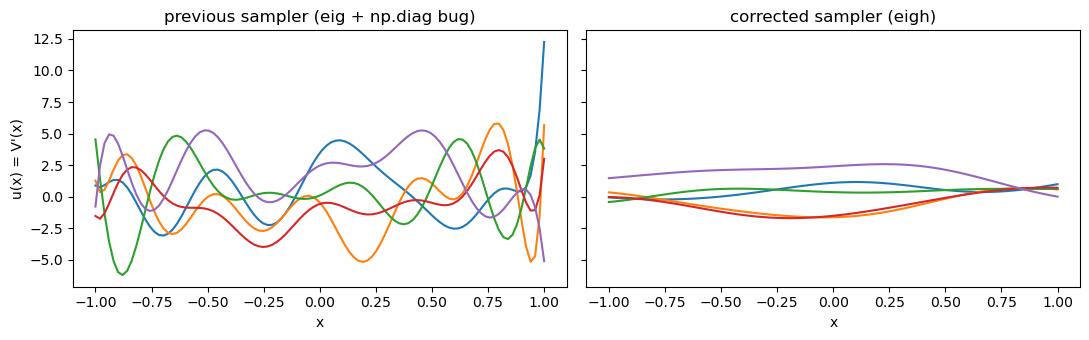

In [3]:
E_old, V_old = np.linalg.eig(Cov)
ind = np.argwhere(np.real(E_old) > 1e-8)
V_old = np.real(V_old)
Cov_sqrt_old = (V_old[:, ind] @ np.diag(np.sqrt(np.real(E_old[ind]))) @ np.transpose(V_old[:, ind])).squeeze()

W = rng.standard_normal((Nx, 5000))
u_old, u_new = (Cov_sqrt_old @ W).T, (Cov_sqrt @ W).T
print(f"||Cov_sqrt_old^2 - Cov|| / ||Cov|| = {np.linalg.norm(Cov_sqrt_old @ Cov_sqrt_old - Cov) / np.linalg.norm(Cov):.2f}")
print(f"pointwise std of u  (old): min {u_old.std(0).min():.2f}, max {u_old.std(0).max():.2f}   (should be 1)")
print(f"pointwise std of u  (new): min {u_new.std(0).min():.2f}, max {u_new.std(0).max():.2f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
for j in range(5):
    ax[0].plot(x, u_old[j]); ax[1].plot(x, u_new[j])
ax[0].set_title("previous sampler (eig + np.diag bug)")
ax[1].set_title("corrected sampler (eigh)")
for a in ax: a.set_xlabel("x")
ax[0].set_ylabel("u(x) = V'(x)")
plt.tight_layout()

## 3. Reference solver: Chebyshev spectral collocation

`solve1Dcommittor(N, scale, shift, f, x_f, beta, x_eval)` (in `Committor1D_helpers.py`):
1. builds the Chebyshev differentiation matrix $D$ on the $N+1$ extrema points $x_j=\cos(\pi j/N)$,
2. linearly interpolates the force $f=u$ from the sensor grid to the Chebyshev points,
3. writes $q = \tfrac12(1+x) + v$ with $v(\pm1)=0$ and solves $\big(D^2 - \mathrm{diag}(\beta f)D\big)v = \tfrac{\beta}{2} f$ on the interior points,
4. converts the nodal values into Chebyshev coefficients and evaluates the series at `x_eval` with Clenshaw's recurrence (vectorized via `numpy.polynomial.chebyshev.chebval`).

With $N = 20$ the solver agrees with the closed-form quadrature to about $10^{-5}$. That is far below the DeepONet errors we can expect, so the reference solutions are effectively exact.

max |Chebyshev - quadrature| over 50 samples: 1.8e-05


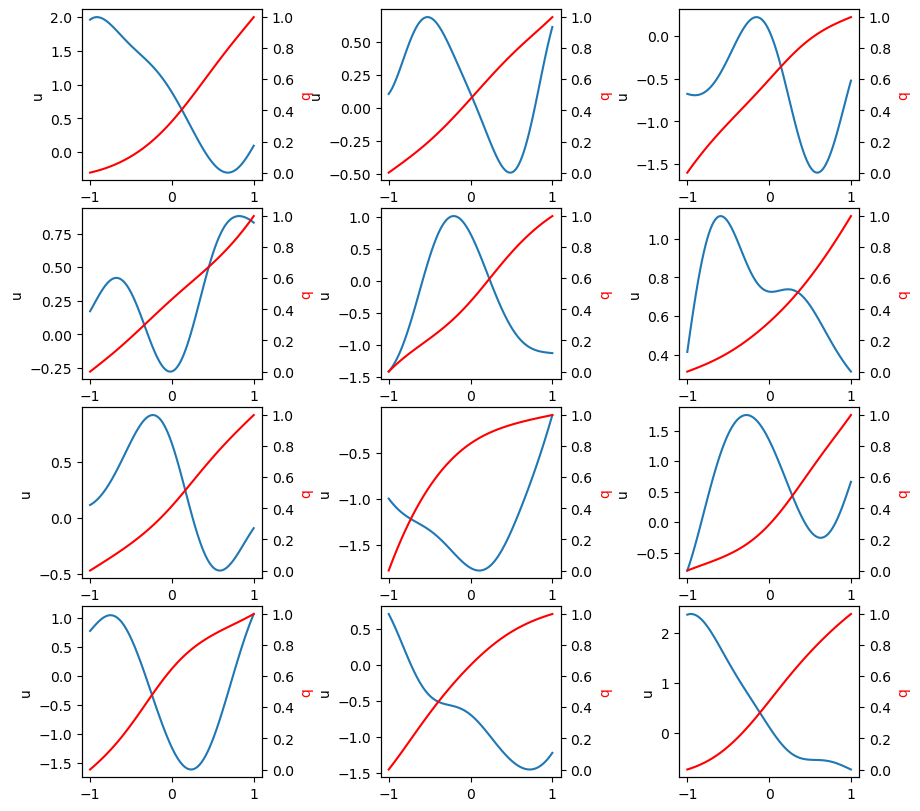

In [4]:
Ncheb = 20
beta = 1.0
scale, shift = 0.5 * (xmax - xmin), 0.5 * (xmin + xmax)   # unused by the solver, kept for compatibility

def committor(u, y):
    # Reference committor for force u (given on the sensor grid x) at points y.
    return solve1Dcommittor(Ncheb, scale, shift, u, x, beta, y)

# Check against the closed-form solution
y_check = np.linspace(xmin, xmax, 257)
err = max(np.abs(committor(u, y_check) - committor_quadrature(u, x, beta, y_check)).max()
          for u in sample_grf(50))
print(f"max |Chebyshev - quadrature| over 50 samples: {err:.1e}")

# Plot a few samples u (blue, left axis) and their committors q (red, right axis)
fig, ax = plt.subplots(4, 3, figsize=(9, 8))
for j, u in enumerate(sample_grf(12)):
    a = ax[j // 3, j % 3]
    a.plot(x, u, label="u")
    a.set_ylabel("u")
    a2 = a.twinx()
    a2.plot(x, committor(u, x), color="red")
    a2.set_ylabel("q", color="red")
plt.tight_layout(pad=0.3)

## 4. The DeepONet architecture

A DeepONet approximates $\mathcal{G}(u)(y)$ by a dot product of two networks:
$$\mathcal{G}(u)(y) \approx \sum_{k=1}^{p} b_k\big(u(x_1),\dots,u(x_{N_x})\big)\, t_k(y) + b_0 .$$
* The **branch net** $b:\mathbb{R}^{N_x}\to\mathbb{R}^p$ reads the input function at the $N_x$ sensors and outputs $p$ coefficients.
* The **trunk net** $t:\mathbb{R}\to\mathbb{R}^p$ takes the query point $y$ and outputs $p$ basis functions. The final $\tanh$ keeps the trunk "basis functions" bounded, as in [1].
* $b_0$ is a scalar trainable bias. The previous version had no bias.

Here the branch has hidden width 80, the trunk has hidden width 40, and $p=40$, the same sizes as before.

**Output transformation.** The committor satisfies $0\le q\le 1$, $q(-1)=0$ and $q(1)=1$. Two choices are implemented:
* `OUTPUT = "sigmoid"`: $q_\theta = \sigma(\langle b,t\rangle + b_0)$, as in the previous version. This guarantees $0<q_\theta<1$, but the boundary values are only learned, and $\sigma$ cannot reach 0 or 1 exactly.
* `OUTPUT = "hard_bc"` (default): $q_\theta(y) = \tfrac12(1+y) + (1-y^2)\,(\langle b,t\rangle + b_0)$. This satisfies **both boundary conditions exactly** for every $u$. The network only has to learn the deviation from the linear profile, which is the committor for $V'\equiv 0$.

Both work well. The hard-constraint version is a little more accurate on random potentials and is a nice example of building known structure into the model.

In [5]:
OUTPUT = "hard_bc"     # "hard_bc" or "sigmoid"

def mlp(sizes, final_activation=False):
    # Fully connected network with tanh activations between layers.
    layers = []
    # zip takes several sequences and pairs up their elements by position. 
    # It yields tuples of the first elements, then the second elements, and so on
    for n_in, n_out in zip(sizes[:-1], sizes[1:]):
        layers += [torch.nn.Linear(n_in, n_out), torch.nn.Tanh()]
    if not final_activation:
        layers = layers[:-1]
    return torch.nn.Sequential(*layers)

class DeepONet(torch.nn.Module):
    def __init__(self, n_sensors, p=40, branch_width=80, trunk_width=40, output="hard_bc"):
        super().__init__()
        self.branch = mlp([n_sensors, branch_width, branch_width, p])            # linear output
        self.trunk = mlp([1, trunk_width, trunk_width, p], final_activation=True)  # tanh on last layer
        self.b0 = torch.nn.Parameter(torch.zeros(1))
        self.output = output

    def forward(self, U, Y):
        # U: (B, Nx) sensor values of B input functions
        # Y: (B, K)  K query points per function, or (K,) shared by all functions
        # returns (B, K)
        b = self.branch(U)                                   # (B, p)
        # Y.unsqueeze(-1) adds a new dimension of length 1 at the end of the tensor. 
        # The values don’t change; only the shape does. 
        # We need it because the trunk net expects inputs with a last dimension of size 1.
        t = self.trunk(Y.unsqueeze(-1))                      # (B, K, p) or (K, p)
        if Y.dim() == 1:
            G = b @ t.T + self.b0                            # same y-points for every u
        else:
            G = torch.einsum("bp,bkp->bk", b, t) + self.b0   # different y-points per u
        if self.output == "sigmoid":
            return torch.sigmoid(G)
        return 0.5 * (1 + Y) + (1 - Y**2) * G                # q(-1)=0, q(1)=1 exactly

model = DeepONet(Nx, output=OUTPUT)
print(model)
print("number of trainable parameters:", sum(p.numel() for p in model.parameters()))

DeepONet(
  (branch): Sequential(
    (0): Linear(in_features=100, out_features=80, bias=True)
    (1): Tanh()
    (2): Linear(in_features=80, out_features=80, bias=True)
    (3): Tanh()
    (4): Linear(in_features=80, out_features=40, bias=True)
  )
  (trunk): Sequential(
    (0): Linear(in_features=1, out_features=40, bias=True)
    (1): Tanh()
    (2): Linear(in_features=40, out_features=40, bias=True)
    (3): Tanh()
    (4): Linear(in_features=40, out_features=40, bias=True)
    (5): Tanh()
  )
)
number of trainable parameters: 21161


## 5. Training and test data

For each of `Ntrain` input functions $u^{(i)}$ we draw `Neval` random query points $y^{(i)}_k\sim U[-1,1]$ and store the reference values $q^{(i)}_k = \mathcal{G}(u^{(i)})(y^{(i)}_k)$.

The data are kept as three arrays: `U` of shape `(Ntrain, Nx)`, `Y` and `Qref` of shape `(Ntrain, Neval)`. The previous version stored a `(Nu*Neval, Nx+2)` table, which duplicated every $u$ `Neval` times and ran the branch net `Neval` times on the same input. With the new layout the branch net runs once per function.

**The number of training functions matters most.** The previous version used only 100 functions. Its training error was about 100× smaller than its test error, which is classic overfitting in function space: 100 samples don't cover the GRF well enough. With the fast solver we can afford 2000 functions; generating them takes under a second.

We also create a **validation set**: 200 new functions on a uniform grid of 128 points, used to monitor generalization during training. A separate **test set** of 1000 functions is used only at the end.

In [6]:
def make_dataset(n_functions, y_points=None, n_eval=100):
    # If y_points is None, draw n_eval random points per function; otherwise use the given grid for all.
    U = sample_grf(n_functions)
    if y_points is None:
        Y = rng.uniform(xmin, xmax, size=(n_functions, n_eval))
        Qref = np.stack([committor(U[i], Y[i]) for i in range(n_functions)])
    else:
        Y = np.asarray(y_points)
        Qref = np.stack([committor(U[i], Y) for i in range(n_functions)])
    as_t = lambda a: torch.tensor(a, dtype=torch.float32)
    return as_t(U), as_t(Y), as_t(Qref)

Ntrain, Neval = 2000, 100
Nvals = 128
y_grid = np.linspace(xmin, xmax, Nvals)
Y_grid = torch.tensor(y_grid, dtype=torch.float32)   # shared evaluation grid for val/test

t0 = time.time()
U_train, Y_train, Q_train = make_dataset(Ntrain, n_eval=Neval)
U_val, Y_val, Q_val = make_dataset(200, y_points=y_grid)
U_test, Y_test, Q_test = make_dataset(1000, y_points=y_grid)
print(f"data generated in {time.time() - t0:.1f} s")
print("train:", tuple(U_train.shape), tuple(Y_train.shape), tuple(Q_train.shape))
print("val:  ", tuple(U_val.shape), tuple(Y_val.shape), tuple(Q_val.shape))

data generated in 0.8 s
train: (2000, 100) (2000, 100) (2000, 100)
val:   (200, 100) (128,) (200, 128)


## 6. Training

* **Loss:** mean squared error between $q_\theta(u^{(i)})(y^{(i)}_k)$ and the reference values, averaged over a mini-batch of functions and all their query points.
* **Mini-batches:** 64 functions per batch, i.e. $64\times100 = 6400$ point evaluations per step. The previous `batch_size = round(10000/64) = 156` gave 64 batches per epoch of 156 rows each, about 1.5 functions per batch, so the gradient barely changed with the input function.
* **Optimizer:** Adam with learning rate $10^{-3}$, decayed to $10^{-5}$ by a cosine schedule over the whole run. The old `MultiStepLR(milestones=[1000,3000,5000])` never fired because training stopped at epoch 1000, so the learning rate stayed at $10^{-3}$ throughout. That explains why the old loss oscillated near the end (for example, the jump to $1.4\cdot10^{-5}$ at epoch 950).
* **No `requires_grad` on the data:** gradients are needed only for the network parameters. Tracking gradients of a 10000×102 data tensor only slows the computation.
* Every few epochs we evaluate the validation MSE under `torch.no_grad()`.

On a laptop CPU this takes about 1–2 minutes. The previous version took 11 484 s of CPU time.

In [7]:
Nepochs = 600
batch_size = 64
n_batches = Ntrain // batch_size

optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=Nepochs * n_batches, eta_min=1e-5)

train_loss = np.zeros(Nepochs)
val_epochs, val_loss = [], []

start_cpu, start_wall = time.process_time(), time.time()
for epoch in range(Nepochs):
    model.train()
    perm = torch.randperm(Ntrain)
    running = 0.0
    for i in range(n_batches):
        idx = perm[i * batch_size:(i + 1) * batch_size]
        pred = model(U_train[idx], Y_train[idx])
        loss = torch.mean((pred - Q_train[idx])**2)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        scheduler.step()              # cosine schedule is stepped once per iteration
        running += loss.item()
    train_loss[epoch] = running / n_batches

    if epoch % 10 == 0 or epoch == Nepochs - 1:
        model.eval()
        with torch.no_grad():
            val_epochs.append(epoch)
            val_loss.append(torch.mean((model(U_val, Y_grid) - Q_val)**2).item())
    if epoch % 50 == 0 or epoch == Nepochs - 1:
        print(f"Epoch {epoch:4d}: train loss {train_loss[epoch]:.3e}, val MSE {val_loss[-1]:.3e}, "
              f"lr {scheduler.get_last_lr()[0]:.1e}")

print(f"CPU time: {time.process_time() - start_cpu:.1f} s, wall time: {time.time() - start_wall:.1f} s")

Epoch    0: train loss 4.834e-03, val MSE 6.663e-04, lr 1.0e-03
Epoch   50: train loss 3.917e-05, val MSE 3.709e-05, lr 9.8e-04
Epoch  100: train loss 1.708e-05, val MSE 1.023e-05, lr 9.3e-04
Epoch  150: train loss 1.234e-05, val MSE 1.200e-05, lr 8.5e-04
Epoch  200: train loss 1.297e-05, val MSE 6.106e-06, lr 7.5e-04
Epoch  250: train loss 7.486e-06, val MSE 4.901e-06, lr 6.3e-04
Epoch  300: train loss 3.617e-06, val MSE 2.722e-06, lr 5.0e-04
Epoch  350: train loss 2.211e-06, val MSE 1.663e-06, lr 3.7e-04
Epoch  400: train loss 4.612e-06, val MSE 1.940e-06, lr 2.6e-04
Epoch  450: train loss 1.621e-06, val MSE 1.161e-06, lr 1.5e-04
Epoch  500: train loss 1.236e-06, val MSE 9.236e-07, lr 7.5e-05
Epoch  550: train loss 1.043e-06, val MSE 8.812e-07, lr 2.6e-05
Epoch  599: train loss 9.968e-07, val MSE 8.226e-07, lr 1.0e-05
CPU time: 300.9 s, wall time: 2149.0 s


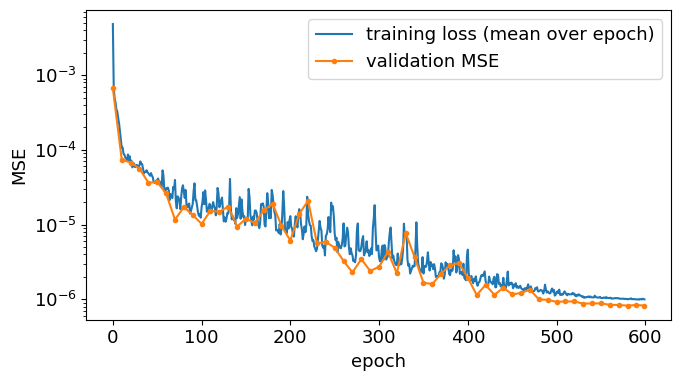

In [8]:
plt.rcParams.update({'font.size': 13})
plt.figure(figsize=(7, 4))
plt.plot(np.arange(Nepochs), train_loss, label="training loss (mean over epoch)")
plt.plot(val_epochs, val_loss, "o-", ms=3, label="validation MSE")
plt.xlabel("epoch"); plt.ylabel("MSE"); plt.yscale("log"); plt.legend()
plt.tight_layout()

The training and validation curves stay close together, so the model generalizes to new potentials: 2000 functions are enough to cover the GRF. With about 100 functions from the previous (buggy) sampler, the test error was about 40 times the training error. With the corrected sampler, 100 functions still leave the test MSE around $2\cdot10^{-4}$. You can try this by setting `Ntrain = 128` (and `batch_size = 16`).

## 7. Test on new random potentials

We evaluate the trained network on the 1000 unseen test functions, on a uniform grid of 128 points. The metrics are:
* MSE and RMSE averaged over all functions and points. These are the same metrics as in the previous version, so they can be compared directly.
* the relative $L^2$ error $\|q_\theta - q\|_2 / \|q\|_2$ per function, which is the standard metric in the DeepONet literature,
* the worst-case pointwise error.

The 18 plots show the first 18 test functions.

Test set (1000 functions): MSE = 1.08e-06, RMSE = 1.04e-03
Compare this error to the previous version: MSE = 6.80e-05, RMSE = 8.24e-03
relative L2 error: mean 1.50e-03, median 1.10e-03, max 1.43e-02
max pointwise error: 1.38e-02


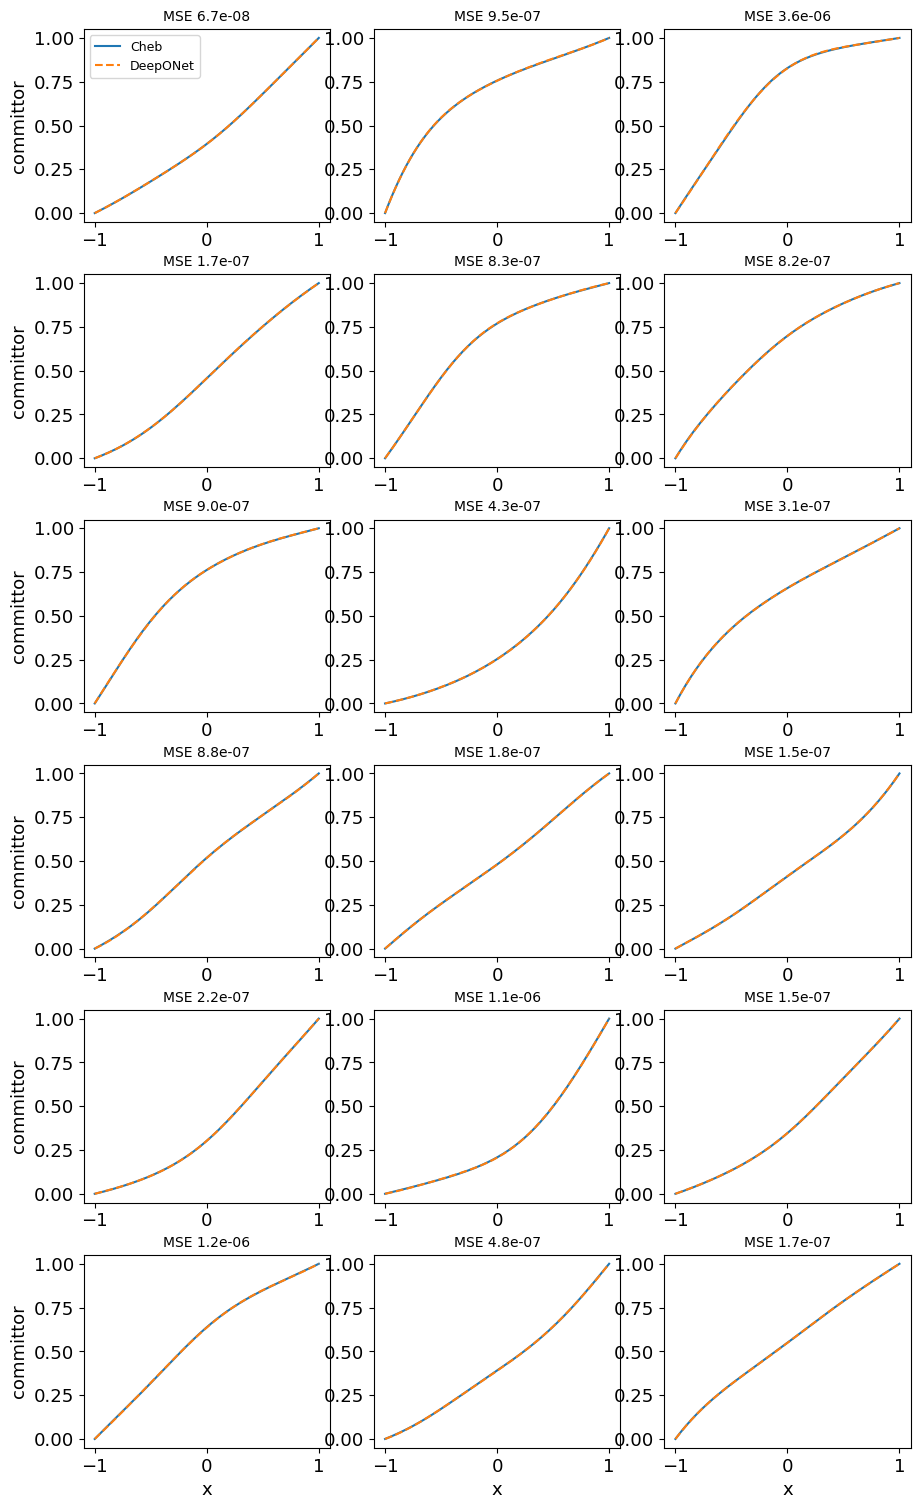

In [9]:
model.eval()
with torch.no_grad():
    Q_pred = model(U_test, Y_grid).numpy()
Q_ref = Q_test.numpy()

err = Q_pred - Q_ref
mse_per_fn = np.mean(err**2, axis=1)
rel_l2 = np.linalg.norm(err, axis=1) / np.linalg.norm(Q_ref, axis=1)
test_MSE = mse_per_fn.mean()
print(f"Test set ({len(Q_ref)} functions): MSE = {test_MSE:.2e}, RMSE = {np.sqrt(test_MSE):.2e}")
print("Compare this error to the previous version: MSE = 6.80e-05, RMSE = 8.24e-03")
print(f"relative L2 error: mean {rel_l2.mean():.2e}, median {np.median(rel_l2):.2e}, max {rel_l2.max():.2e}")
print(f"max pointwise error: {np.abs(err).max():.2e}")

fig, ax = plt.subplots(6, 3, figsize=(9, 15))
for j in range(18):
    a = ax[j // 3, j % 3]
    a.plot(y_grid, Q_ref[j], label="Cheb")
    a.plot(y_grid, Q_pred[j], "--", label="DeepONet")
    a.set_title(f"MSE {mse_per_fn[j]:.1e}", fontsize=10)
    if j % 3 == 0: a.set_ylabel("committor")
    if j >= 15: a.set_xlabel("x")
ax[0, 0].legend(fontsize=9)
plt.tight_layout(pad=0.3)

Plotting the error itself is more informative than overlaying the curves, which are indistinguishable at this accuracy. With `OUTPUT = "hard_bc"` the error vanishes at $x=\pm1$ by construction.

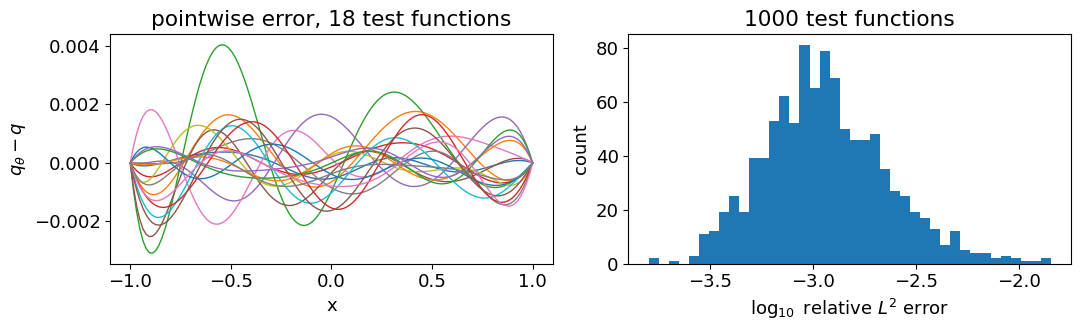

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for j in range(18):
    ax[0].plot(y_grid, err[j], lw=1)
ax[0].set_xlabel("x"); ax[0].set_ylabel(r"$q_\theta - q$"); ax[0].set_title("pointwise error, 18 test functions")
ax[1].hist(np.log10(rel_l2), bins=40)
ax[1].set_xlabel(r"$\log_{10}$ relative $L^2$ error"); ax[1].set_ylabel("count"); ax[1].set_title("1000 test functions")
plt.tight_layout()

## 8. Performance on the training data

This is the same check as before: the error on the first 18 training functions, at their own random query points. The previous cell indexed the table with `Nx` instead of `Neval`, which only worked because both equal 100. It also printed the training RMSE under the label `test_error`.

training RMSE per function: [5.4e-04, 8.2e-04, 2.1e-03, 2.4e-04, 4.5e-04, 9.0e-04, 5.1e-04, 1.3e-03,
 8.5e-04, 1.1e-03, 3.0e-04, 5.9e-04, 3.8e-04, 7.7e-04, 3.0e-04, 9.1e-04,
 8.0e-04, 3.6e-04]
MSE over the whole training set: 9.93e-07   (test MSE 1.08e-06)


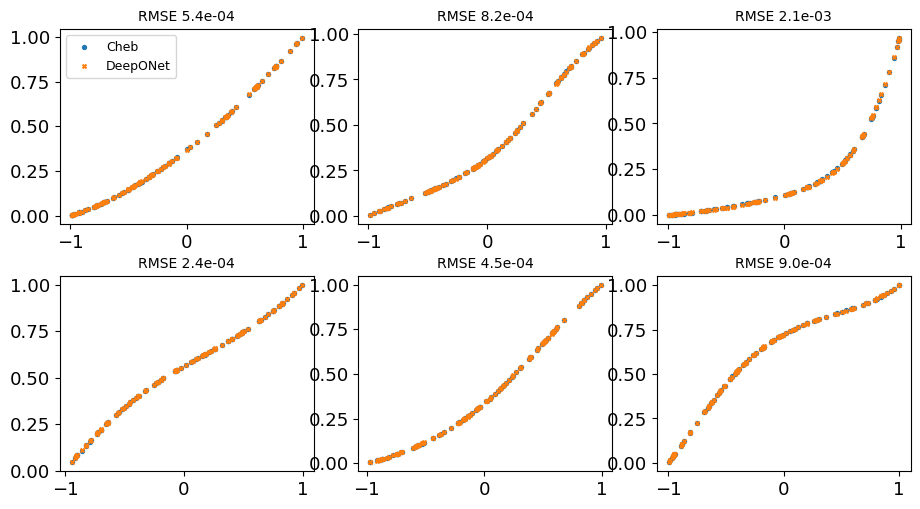

In [11]:
with torch.no_grad():
    Q_fit = model(U_train[:18], Y_train[:18]).numpy()
train_rmse = np.sqrt(np.mean((Q_fit - Q_train[:18].numpy())**2, axis=1))
print("training RMSE per function:", np.array2string(train_rmse, formatter={"float_kind": lambda v: f"{v:.1e}"}, separator=", "))

with torch.no_grad():
    full_train_mse = torch.mean((model(U_train, Y_train) - Q_train)**2).item()
print(f"MSE over the whole training set: {full_train_mse:.2e}   (test MSE {test_MSE:.2e})")

fig, ax = plt.subplots(2, 3, figsize=(9, 5))
for j in range(6):
    a = ax[j // 3, j % 3]
    a.scatter(Y_train[j], Q_train[j], s=8, label="Cheb")
    a.scatter(Y_train[j], Q_fit[j], s=8, marker="x", label="DeepONet")
    a.set_title(f"RMSE {train_rmse[j]:.1e}", fontsize=10)
ax[0, 0].legend(fontsize=9)
plt.tight_layout(pad=0.3)

## 9. A double-well potential

For $V(x) = (x^2-1)^2$ we have $u = V'(x) = 4(x^3-x)$. This force is not a sample from the GRF, but its size ($\max|u|\approx1.54$) is typical for the corrected GRF, whose samples have pointwise standard deviation 1. The previous sampler produced samples that were 2–6 times larger and much rougher, so the smooth double-well force was poorly represented in that training set.

Double-well test: MSE = 5.42e-07, RMSE = 7.36e-04, max error = 1.13e-03


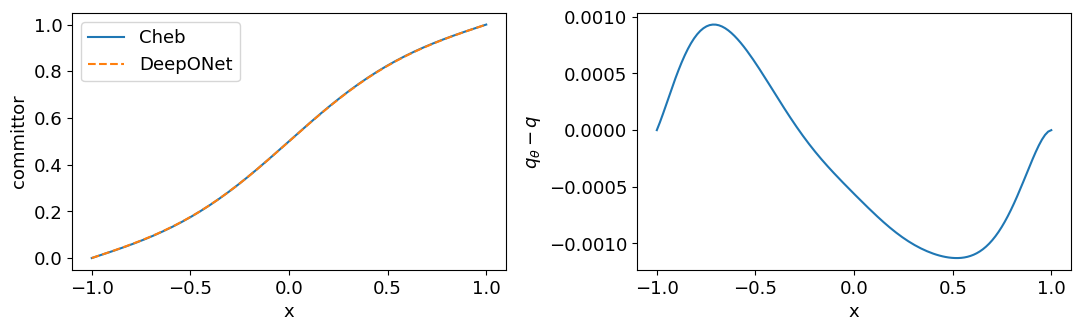

In [12]:
u_dw = 4 * (x**3 - x)
q_dw = committor(u_dw, y_grid)
with torch.no_grad():
    q_dw_pred = model(torch.tensor(u_dw, dtype=torch.float32)[None], Y_grid).numpy()[0]
dw_MSE = np.mean((q_dw_pred - q_dw)**2)
print(f"Double-well test: MSE = {dw_MSE:.2e}, RMSE = {np.sqrt(dw_MSE):.2e}, "
      f"max error = {np.abs(q_dw_pred - q_dw).max():.2e}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(y_grid, q_dw, label="Cheb")
ax[0].plot(y_grid, q_dw_pred, "--", label="DeepONet")
ax[0].set_xlabel("x"); ax[0].set_ylabel("committor"); ax[0].legend()
ax[1].plot(y_grid, q_dw_pred - q_dw)
ax[1].set_xlabel("x"); ax[1].set_ylabel(r"$q_\theta - q$")
plt.tight_layout()

## 10. (Optional) Evaluating the trained DeepONet in NumPy

The previous version copied each weight matrix into NumPy by hand. The function below does the same for any `nn.Sequential` of `Linear`/`Tanh` layers and checks that it reproduces the PyTorch output. This is useful if you want to use the trained operator in code that doesn't depend on PyTorch.

In [13]:
def to_numpy_layers(seq):
    # Extract a list of ('linear', W, b) / ('tanh',) from an nn.Sequential.
    out = []
    for layer in seq:
        if isinstance(layer, torch.nn.Linear):
            out.append(("linear", layer.weight.detach().numpy().astype(np.float64),
                        layer.bias.detach().numpy().astype(np.float64)))
        elif isinstance(layer, torch.nn.Tanh):
            out.append(("tanh",))
    return out

def np_forward(layers, z):
    for L in layers:
        z = z @ L[1].T + L[2] if L[0] == "linear" else np.tanh(z)
    return z

branch_np, trunk_np = to_numpy_layers(model.branch), to_numpy_layers(model.trunk)
b0_np = model.b0.item()

def deeponet_numpy(u, y):
    # u: (Nx,) sensor values, y: (K,) query points -> (K,)
    G = np_forward(trunk_np, y[:, None]) @ np_forward(branch_np, u) + b0_np
    if model.output == "sigmoid":
        return 1 / (1 + np.exp(-G))
    return 0.5 * (1 + y) + (1 - y**2) * G

diff = np.abs(deeponet_numpy(u_dw, y_grid) - q_dw_pred).max()
print(f"max |NumPy - PyTorch| on the double well: {diff:.1e}  (float32 round-off)")

max |NumPy - PyTorch| on the double well: 7.3e-08  (float32 round-off)


## 11. Summary

In [15]:
old = dict(test_MSE=3.37e-3, dw_MSE=7.88e-3, cpu=11484.7)
new = dict(test_MSE=test_MSE, dw_MSE=dw_MSE)
print(f"{'':28s}{'previous':>12s}{'this notebook':>16s}{'improvement':>14s}")
print(f"{'random potentials, MSE':28s}{old['test_MSE']:12.2e}{new['test_MSE']:16.2e}{old['test_MSE']/new['test_MSE']:13.0f}x")
print(f"{'random potentials, RMSE':28s}{np.sqrt(old['test_MSE']):12.2e}{np.sqrt(new['test_MSE']):16.2e}{np.sqrt(old['test_MSE']/new['test_MSE']):13.0f}x")
print(f"{'double well, MSE':28s}{old['dw_MSE']:12.2e}{new['dw_MSE']:16.2e}{old['dw_MSE']/new['dw_MSE']:13.0f}x")
print(f"{'double well, RMSE':28s}{np.sqrt(old['dw_MSE']):12.2e}{np.sqrt(new['dw_MSE']):16.2e}{np.sqrt(old['dw_MSE']/new['dw_MSE']):13.0f}x")

                                previous   this notebook   improvement
random potentials, MSE          3.37e-03        1.08e-06         3122x
random potentials, RMSE         5.81e-02        1.04e-03           56x
double well, MSE                7.88e-03        5.42e-07        14535x
double well, RMSE               8.88e-02        7.36e-04          121x


### Learning-rate schedule: cosine annealing

Cosine annealing is a learning-rate schedule. Instead of keeping the learning rate fixed or cutting it in discrete steps, it lowers it smoothly from a maximum $\eta_{\max}$ to a minimum $\eta_{\min}$ along half a cosine wave:
$$
\eta_t \;=\; \eta_{\min} + \tfrac12\,(\eta_{\max}-\eta_{\min})\Big(1+\cos\frac{\pi t}{T}\Big),\qquad t = 0,1,\dots,T .
$$
At $t=0$ the cosine is 1, so $\eta_0=\eta_{\max}$. At $t=T$ it is $-1$, so $\eta_T=\eta_{\min}$.

**Parameters used here**

- $\eta_{\max} = 10^{-3}$ is the learning rate given to Adam (`lr=1e-3`). The scheduler takes it as the starting value.
- $\eta_{\min} = 10^{-5}$ is `eta_min`.
- $T$ = `T_max = Nepochs * n_batches` $= 600 \times 31 = 18\,600$. This is counted in **optimizer steps**, not epochs, because `scheduler.step()` is called after every mini-batch. The rate therefore decreases a little at every iteration and reaches $10^{-5}$ exactly at the last step. Halfway through, at epoch 300, the rate is $\approx 5\cdot10^{-4}$.

**Shape of the curve**

- **Early:** the rate stays near $10^{-3}$ for a long time, since the cosine is flat near 0. Large steps make fast progress while the loss is still large.
- **Middle:** the rate drops fastest.
- **Late:** the rate flattens out near $10^{-5}$, so the last part of training is spent fine-tuning with small steps.

**Why decaying the rate helps**

With mini-batches the gradient is noisy. With a constant step size $\eta$, the parameters don't settle at a minimum; they keep moving around it, and the loss stalls at a level that grows with $\eta$. In the previous version of this notebook, the `MultiStepLR` milestones (1000, 3000, 5000) were never reached in 1000 epochs. The rate stayed at $10^{-3}$, and the loss bounced (e.g. $3.4\cdot10^{-6}$ at epoch 900, then $1.4\cdot10^{-5}$ at epoch 950). Shrinking $\eta$ at the end reduces that noise, and the training loss falls smoothly.

Compared with step schedules like `MultiStepLR`, there are no milestones to choose. You only set the total length and the final rate, and the schedule automatically adapts to the number of epochs.

**Reference.** I. Loshchilov and F. Hutter, *SGDR: Stochastic Gradient Descent with Warm Restarts*, ICLR 2017. There the cosine is restarted periodically ("warm restarts"); PyTorch implements that version as `CosineAnnealingWarmRestarts`. `CosineAnnealingLR` with `T_max` equal to the full run, as used here, is a single decay with no restart.

**Where the improvement comes from.** These are rough ablations with the new training loop and the same network sizes, using shorter runs than above:

| sampler | training functions | epochs | output | test MSE (train MSE) |
|---|---|---|---|---|
| previous (buggy) | 128 | 1000 | sigmoid | $7.5\cdot10^{-3}$ ($1.8\cdot10^{-4}$), reproduces the previous regime |
| previous (buggy) | 2000 | 200 | hard BC | $9.4\cdot10^{-5}$ |
| corrected | 128 | 1000 | sigmoid | $2.0\cdot10^{-4}$ |
| corrected | 2000 | 200 | hard BC | $1.2\cdot10^{-5}$ |
| corrected | 2000 | 600 | hard BC | $\approx 10^{-6}$ (this notebook) |

* **Too few training functions** was the main cause of the large test error. With 128 functions the model fits the training set well but doesn't generalize to new $u$, which is overfitting in function space.
* **The sampler bug** made the input functions rough and large, so the operator was harder to learn and the smooth double-well force was poorly represented in the training data.
* **Batching by functions and the cosine schedule** cut the cost per epoch by about 100× and give a smooth final convergence. The old learning rate never decayed.
* **Exact boundary conditions and the bias $b_0$** give a modest further gain and remove errors at $x=\pm1$.

The previous random-potential errors were measured on samples from the buggy sampler, so the comparison in the table above is not on identical distributions. The second row of the ablation table shows that the new training loop with 2000 functions also does well on the old distribution.

**Suggestions for exercises**
* Set `Ntrain = 100, 200, 500, 1000, 2000` and plot the test error against the number of training functions.
* Compare `OUTPUT = "sigmoid"` and `OUTPUT = "hard_bc"`.
* Vary the correlation length $l$ or $\beta$. Smaller $l$ or larger $\beta$ give sharper committors and a harder operator.
* Test on potentials outside the training distribution, e.g. $u = 4c(x^3 - x)$ with growing $c$, and watch the error grow.